**Load Data**

In [ ]:
!pip install numpy matplotlib seaborn pandas openpyxl smogn xgboost sklearn


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
import re
from scipy.stats import gmean
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.model_selection import GridSearchCV, cross_validate, KFold, cross_val_predict, train_test_split
from sklearn.ensemble import StackingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import BaggingRegressor

In [33]:
wqi_data = pd.read_csv('quang_ninh_wqi_v3.csv')

In [34]:
print("Dataset from file quang_ninh_wqi_v3:")
print(wqi_data.head())

Dataset from file quang_ninh_wqi_v3:
                                            Location Sample ID    Month  \
0  Sông Vàng Danh phía sau điểm hợp lưu với ...       NM8    Qúy I   
1  Sông Vàng Danh phía sau điểm hợp lưu với ...       NM8   Qúy II   
2  Sông Vàng Danh phía sau điểm hợp lưu với ...       NM8  Qúy III   
3  Sông Vàng Danh phía sau điểm hợp lưu với ...       NM8   Qúy IV   
4                                        Suối 12 Khe       NM9    Qúy I   

  Nhiệt độ (0C)    pH DO mg/l Salinity Turbidity TSS mg/l COD mg/l  ...  \
0          21,5   7,9    8,23      NaN       NaN     27,4      9,8  ...   
1          24,1  7,29    7,28      NaN       NaN     30,4     10,2  ...   
2          28,4  6,81    7,18      NaN       NaN     94,2     19,2  ...   
3          26,7  7,42    6,25      NaN       NaN     75,2     15,2  ...   
4          17,1  6,31    7,44      NaN       NaN     11,1      5,3  ...   

  Cr(VI) Tổng phenol Tổng hoạt độ phóng xạ α Tổng hoạt độ phó

# 1. Data Pre-processing


---






In [35]:
wqi_data.rename(columns={
    'Location': 'Location',
    'Sample ID': 'Sample_ID',
    'Month': 'Month',
    'Nhiệt độ (0C)': 'Temperature_C',
    'pH': 'pH',
    'DO mg/l': 'DO_mg_L',
    'Salinity': 'Salinity',
    'Turbidity': 'Turbidity',
    'TSS mg/l': 'TSS_mg_L',
    'COD mg/l': 'COD_mg_L',
    'BOD5 mg/l': 'BOD5_mg_L',
    'SO42-mg/l': 'SO4_mg_L',
    'NO3-mg/l': 'NO3_mg_L',
    'NO2-mg/l ': 'NO2_mg_L',
    'NH4+ mg/l': 'NH4_mg_L',
    'PO43- mg/l ': 'PO4_mg_L',
    'MBAS': 'MBAS',
    'Xianua': 'Cyanide',
    'Florua': 'Fluoride',
    'Cl - mg/l': 'Cl_mg_L',
    'Tổng dầu, mỡ mg/l': 'Total_Oil_Fat_mg_L',
    'Coliform MPN/100ml': 'Coliform_MPN_100ml',
    'E.Coli': 'EColi',
    'As mg/l': 'As_mg_L',
    'Hg mg/l': 'Hg_mg_L',
    'Pb mg/l': 'Pb_mg_L',
    'Cd mg/l': 'Cd_mg_L',
    'Fe mg/l': 'Fe_mg_L',
    'Mn': 'Mn',
    'Cu': 'Cu',
    'Ni': 'Ni',
    'Zn': 'Zn',
    'Cr': 'Cr',
    'Cr(VI)': 'CrVI',
    'Tổng phenol': 'Total_Phenol',
    'Tổng hoạt độ phóng xạ α': 'Total_Rad_Alpha',
    'Tổng hoạt độ phóng xạ β': 'Total_Rad_Beta',
    'Aldrin': 'Aldrin',
    'BHC': 'BHC',
    'Dieldrin': 'Dieldrin',
    'DDTs': 'DDTs',
    'Heptachlor & Heptachloreproxide': 'Heptachlor_Proxide',
    'TOC': 'TOC'
}, inplace=True)


Location: Sampling location

Sample_ID: Unique sample identifier

Month: Monitoring month

Temperature_C: Water temperature in Celsius

pH: pH level

DO_mg_L: Dissolved Oxygen in mg/L

Salinity: Salinity of water

Turbidity: Water turbidity

TSS_mg_L: Total Suspended Solids in mg/L

COD_mg_L: Chemical Oxygen Demand in mg/L

BOD5_mg_L: Biochemical Oxygen Demand over 5 days in mg/L

SO4_mg_L: Sulfate concentration in mg/L

NO3_mg_L: Nitrate concentration in mg/L

NO2_mg_L: Nitrite concentration in mg/L

NH4_mg_L: Ammonium concentration in mg/L

PO4_mg_L: Phosphate concentration in mg/L

MBAS: Surfactant content (MBAS method)

Cyanide: Cyanide concentration

Fluoride: Fluoride concentration

Cl_mg_L: Chloride concentration in mg/L

Total_Oil_Fat_mg_L: Total oil and fat content in mg/L

Coliform_MPN_100ml: Coliform bacteria count (MPN/100ml)

EColi: E. Coli bacteria count

As_mg_L: Arsenic concentration in mg/L

Hg_mg_L: Mercury concentration in mg/L

Pb_mg_L: Lead concentration in mg/L

Cd_mg_L: Cadmium concentration in mg/L

Fe_mg_L: Iron concentration in mg/L

Mn: Manganese concentration

Cu: Copper concentration

Ni: Nickel concentration

Zn: Zinc concentration

Cr: Chromium concentration

CrVI: Hexavalent Chromium concentration

Total_Phenol: Total phenol content

Total_Rad_Alpha: Total alpha radioactivity

Total_Rad_Beta: Total beta radioactivity

Aldrin: Aldrin pesticide concentration

BHC: BHC pesticide concentration

Dieldrin: Dieldrin pesticide concentration

DDTs: DDT and its derivatives concentration

Heptachlor_Proxide: Heptachlor & Heptachloreproxide concentration

TOC: Total Organic Carbon


In [36]:
wqi_data_droped = wqi_data.drop([
    'Location', 'Sample_ID', 'Month', 'Salinity', 'Turbidity', 'TSS_mg_L', 'SO4_mg_L', 'MBAS', 'Cyanide', 'Fluoride',
    'Cl_mg_L', 'Total_Oil_Fat_mg_L', 'Fe_mg_L', 'Mn', 'Cu', 'Ni', 'Zn', 'Total_Phenol',
    'Total_Rad_Alpha', 'Total_Rad_Beta'
], axis=1)


Drop some columns which don't impact to WQI scores

## Unique values

Find out unique values in columns. This will help you in identifying in-consistent data.

In [37]:
# <<< Your code here >>>

## 1.1 Missing Values

Identify and handle missing values.

In [38]:
wqi_data_filled = wqi_data_droped.replace('X', np.nan)
wqi_data_filled = wqi_data_droped.replace('x', np.nan)
wqi_data_filled.isnull().sum()

Temperature_C           0
pH                      0
DO_mg_L                 0
COD_mg_L                0
BOD5_mg_L               0
NO3_mg_L                0
NO2_mg_L                0
NH4_mg_L                0
PO4_mg_L                0
Coliform_MPN_100ml      0
EColi                 156
As_mg_L                 0
Hg_mg_L                 0
Pb_mg_L                 0
Cd_mg_L                 0
Cr                    156
CrVI                  156
Aldrin                766
BHC                   766
Dieldrin              766
DDTs                  766
Heptachlor_Proxide    766
TOC                   767
dtype: int64

Some cells contain 'x' instead of being empty, so the missing values were standardized and the number of missing values was calculated.


In [39]:
wqi_data_droped_v2 = wqi_data_filled.drop([
    'Cr', 'Aldrin', 'BHC', 'Dieldrin', 'DDTs', 'Heptachlor_Proxide', 'TOC'
], axis=1)

print(wqi_data_droped_v2.head())

  Temperature_C    pH DO_mg_L COD_mg_L BOD5_mg_L NO3_mg_L NO2_mg_L NH4_mg_L  \
0          21,5   7,9    8,23      9,8       4,5    0,747    0,064    0,154   
1          24,1  7,29    7,28     10,2       4,7    0,434     0,06    0,215   
2          28,4  6,81    7,18     19,2       7,2    0,492   <0,002    0,232   
3          26,7  7,42    6,25     15,2       5,4    0,266   <0,002    0,522   
4          17,1  6,31    7,44      5,3       1,8    0,865    0,023    0,096   

  PO4_mg_L Coliform_MPN_100ml EColi As_mg_L  Hg_mg_L  Pb_mg_L  Cd_mg_L CrVI  
0    0,024                400   NaN  0,0004  <0,0003  <0,0007  <0,0006  NaN  
1     0,01               2000   NaN  0,0005  <0,0003  <0,0007  <0,0006  NaN  
2    0,057               4500   NaN  0,0004  <0,0003   0,0018   0,0007  NaN  
3    0,098               7000   NaN  0,0006  <0,0003   0,0011  <0,0006  NaN  
4    0,048                 40   NaN  0,0003  <0,0003   0,0001  <0,0006  NaN  


Columns with about 75% missing values were removed.

In [40]:
wqi_data_cleaned = wqi_data_droped_v2[~wqi_data_droped_v2.apply(lambda row: row.astype(str).str.contains(r'\s*KCM\s*', regex=True).any(), axis=1)]

KCM: Value could not be measured; these records were removed from the dataset

## 1.2 Column, Cell data type conversion

In [41]:
def handle_less_than_numeric(val):
    # If the value is a string
    if isinstance(val, str):
        val = val.strip()
        # If it matches the pattern "<x" or "<x.y"
        match = re.fullmatch(r'<\s*([0-9,]*\.?[0-9]+)', val)
        if match:
            x_str = match.group(1).replace(',', '.')
            return float(x_str)
        # If it's a numeric string with comma or dot
        try:
            return float(val.replace(',', '.'))
        except ValueError:
            return val
    # If it's already a number, keep as is
    elif isinstance(val, (int, float)):
        return val
    # Other values remain unchanged
    return val

def convert_column_type(col):
    # Remove NaN to check
    non_na = col.dropna()

    # Check if all are numbers
    if non_na.apply(lambda x: isinstance(x, (int, float))).all():
        return col.astype(float)
    else:
        return col.astype('category')


# Apply the conversion to handle "<" and numeric strings
wqi_data_cleaned_v2 = wqi_data_cleaned.applymap(handle_less_than_numeric)

# Convert all to numeric (if not a number → NaN)
wqi_data_convert_cell = wqi_data_cleaned_v2.apply(convert_column_type)

print(wqi_data_convert_cell.head())

   Temperature_C    pH  DO_mg_L  COD_mg_L  BOD5_mg_L  NO3_mg_L  NO2_mg_L  \
0           21.5  7.90     8.23       9.8        4.5     0.747     0.064   
1           24.1  7.29     7.28      10.2        4.7     0.434     0.060   
2           28.4  6.81     7.18      19.2        7.2     0.492     0.002   
3           26.7  7.42     6.25      15.2        5.4     0.266     0.002   
4           17.1  6.31     7.44       5.3        1.8     0.865     0.023   

   NH4_mg_L  PO4_mg_L  Coliform_MPN_100ml  EColi  As_mg_L  Hg_mg_L  Pb_mg_L  \
0     0.154     0.024               400.0    NaN   0.0004   0.0003   0.0007   
1     0.215     0.010              2000.0    NaN   0.0005   0.0003   0.0007   
2     0.232     0.057              4500.0    NaN   0.0004   0.0003   0.0018   
3     0.522     0.098              7000.0    NaN   0.0006   0.0003   0.0011   
4     0.096     0.048                40.0    NaN   0.0003   0.0003   0.0001   

   Cd_mg_L  CrVI  
0   0.0006   NaN  
1   0.0006   NaN  
2   0.0007 

C:\Users\Admin\AppData\Local\Temp\ipykernel_6432\1738442683.py:33: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  wqi_data_cleaned_v2 = wqi_data_cleaned.applymap(handle_less_than_numeric)


Cells with values less than x will be converted to type x

In [42]:
wqi_data_convert_cell.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1101 entries, 0 to 1109
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Temperature_C       1101 non-null   float64
 1   pH                  1101 non-null   float64
 2   DO_mg_L             1101 non-null   float64
 3   COD_mg_L            1101 non-null   float64
 4   BOD5_mg_L           1101 non-null   float64
 5   NO3_mg_L            1101 non-null   float64
 6   NO2_mg_L            1101 non-null   float64
 7   NH4_mg_L            1101 non-null   float64
 8   PO4_mg_L            1101 non-null   float64
 9   Coliform_MPN_100ml  1101 non-null   float64
 10  EColi               946 non-null    float64
 11  As_mg_L             1101 non-null   float64
 12  Hg_mg_L             1101 non-null   float64
 13  Pb_mg_L             1101 non-null   float64
 14  Cd_mg_L             1101 non-null   float64
 15  CrVI                946 non-null    float64
dtypes: float64(

There are 2 columns which include missing values that are EColi and CrVI

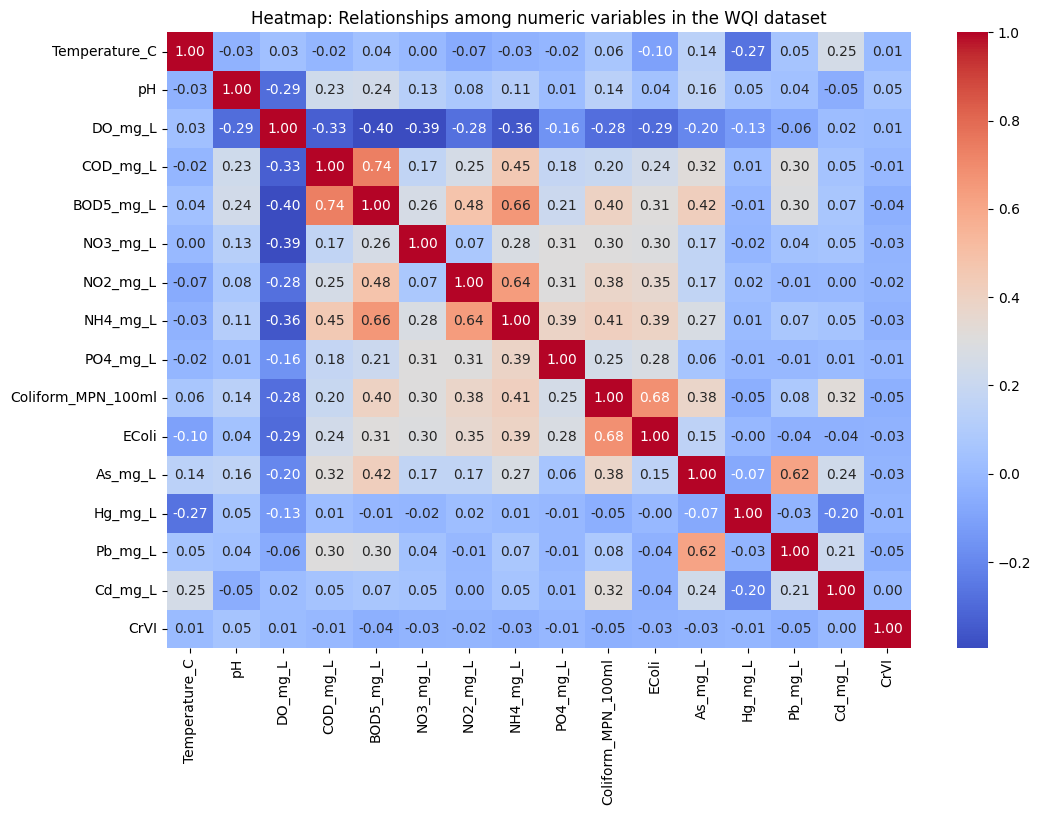

In [43]:
# Select numeric columns
numeric_cols = wqi_data_convert_cell.select_dtypes(include=['int64', 'float64']).columns
df_numeric = wqi_data_convert_cell[numeric_cols]

# Compute the correlation matrix
corr_matrix = df_numeric.corr()

plt.figure(figsize=(12, 8))  # adjust figure size
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Relationships among numeric variables in the WQI dataset")
plt.show()

Because EColi and CrVI do not have any meaningful relationship with the other features, we cannot apply linear regression to predict them.

In [44]:
# List of numeric columns to impute
num_cols_to_impute = ['EColi', 'CrVI']

# List of numeric columns to impute
other_num_cols = [col for col in wqi_data_convert_cell.columns if col not in num_cols_to_impute]

# Create a copy to avoid modifying the original
df = wqi_data_convert_cell.copy()

# Select columns for KNN to work on (can use the entire dataset for KNN to leverage information from other columns)
imputer = KNNImputer(n_neighbors=5)

df[num_cols_to_impute] = imputer.fit_transform(
    df[num_cols_to_impute + other_num_cols]
)[:, :len(num_cols_to_impute)]

wqi_data_convert_cell['EColi'] = df['EColi']
wqi_data_convert_cell['CrVI'] = df['CrVI']

Fill missing values with KNN

In [45]:
wqi_data_convert_cell.isnull().sum()

Temperature_C         0
pH                    0
DO_mg_L               0
COD_mg_L              0
BOD5_mg_L             0
NO3_mg_L              0
NO2_mg_L              0
NH4_mg_L              0
PO4_mg_L              0
Coliform_MPN_100ml    0
EColi                 0
As_mg_L               0
Hg_mg_L               0
Pb_mg_L               0
Cd_mg_L               0
CrVI                  0
dtype: int64

All missing values have already been handled.

## 1.3 Removing Inconsistent values and Outliers


C:\Users\Admin\AppData\Local\Temp\ipykernel_6432\1801114758.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=[0]*len(wqi_data_convert_cell), y=wqi_data_convert_cell[col],
C:\Users\Admin\AppData\Local\Temp\ipykernel_6432\1801114758.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=[0]*len(wqi_data_convert_cell), y=wqi_data_convert_cell[col],
C:\Users\Admin\AppData\Local\Temp\ipykernel_6432\1801114758.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=[0]*len(wqi_data_convert_cell), y=wqi_data_convert_cell[col],
C:\Users\Admin\A

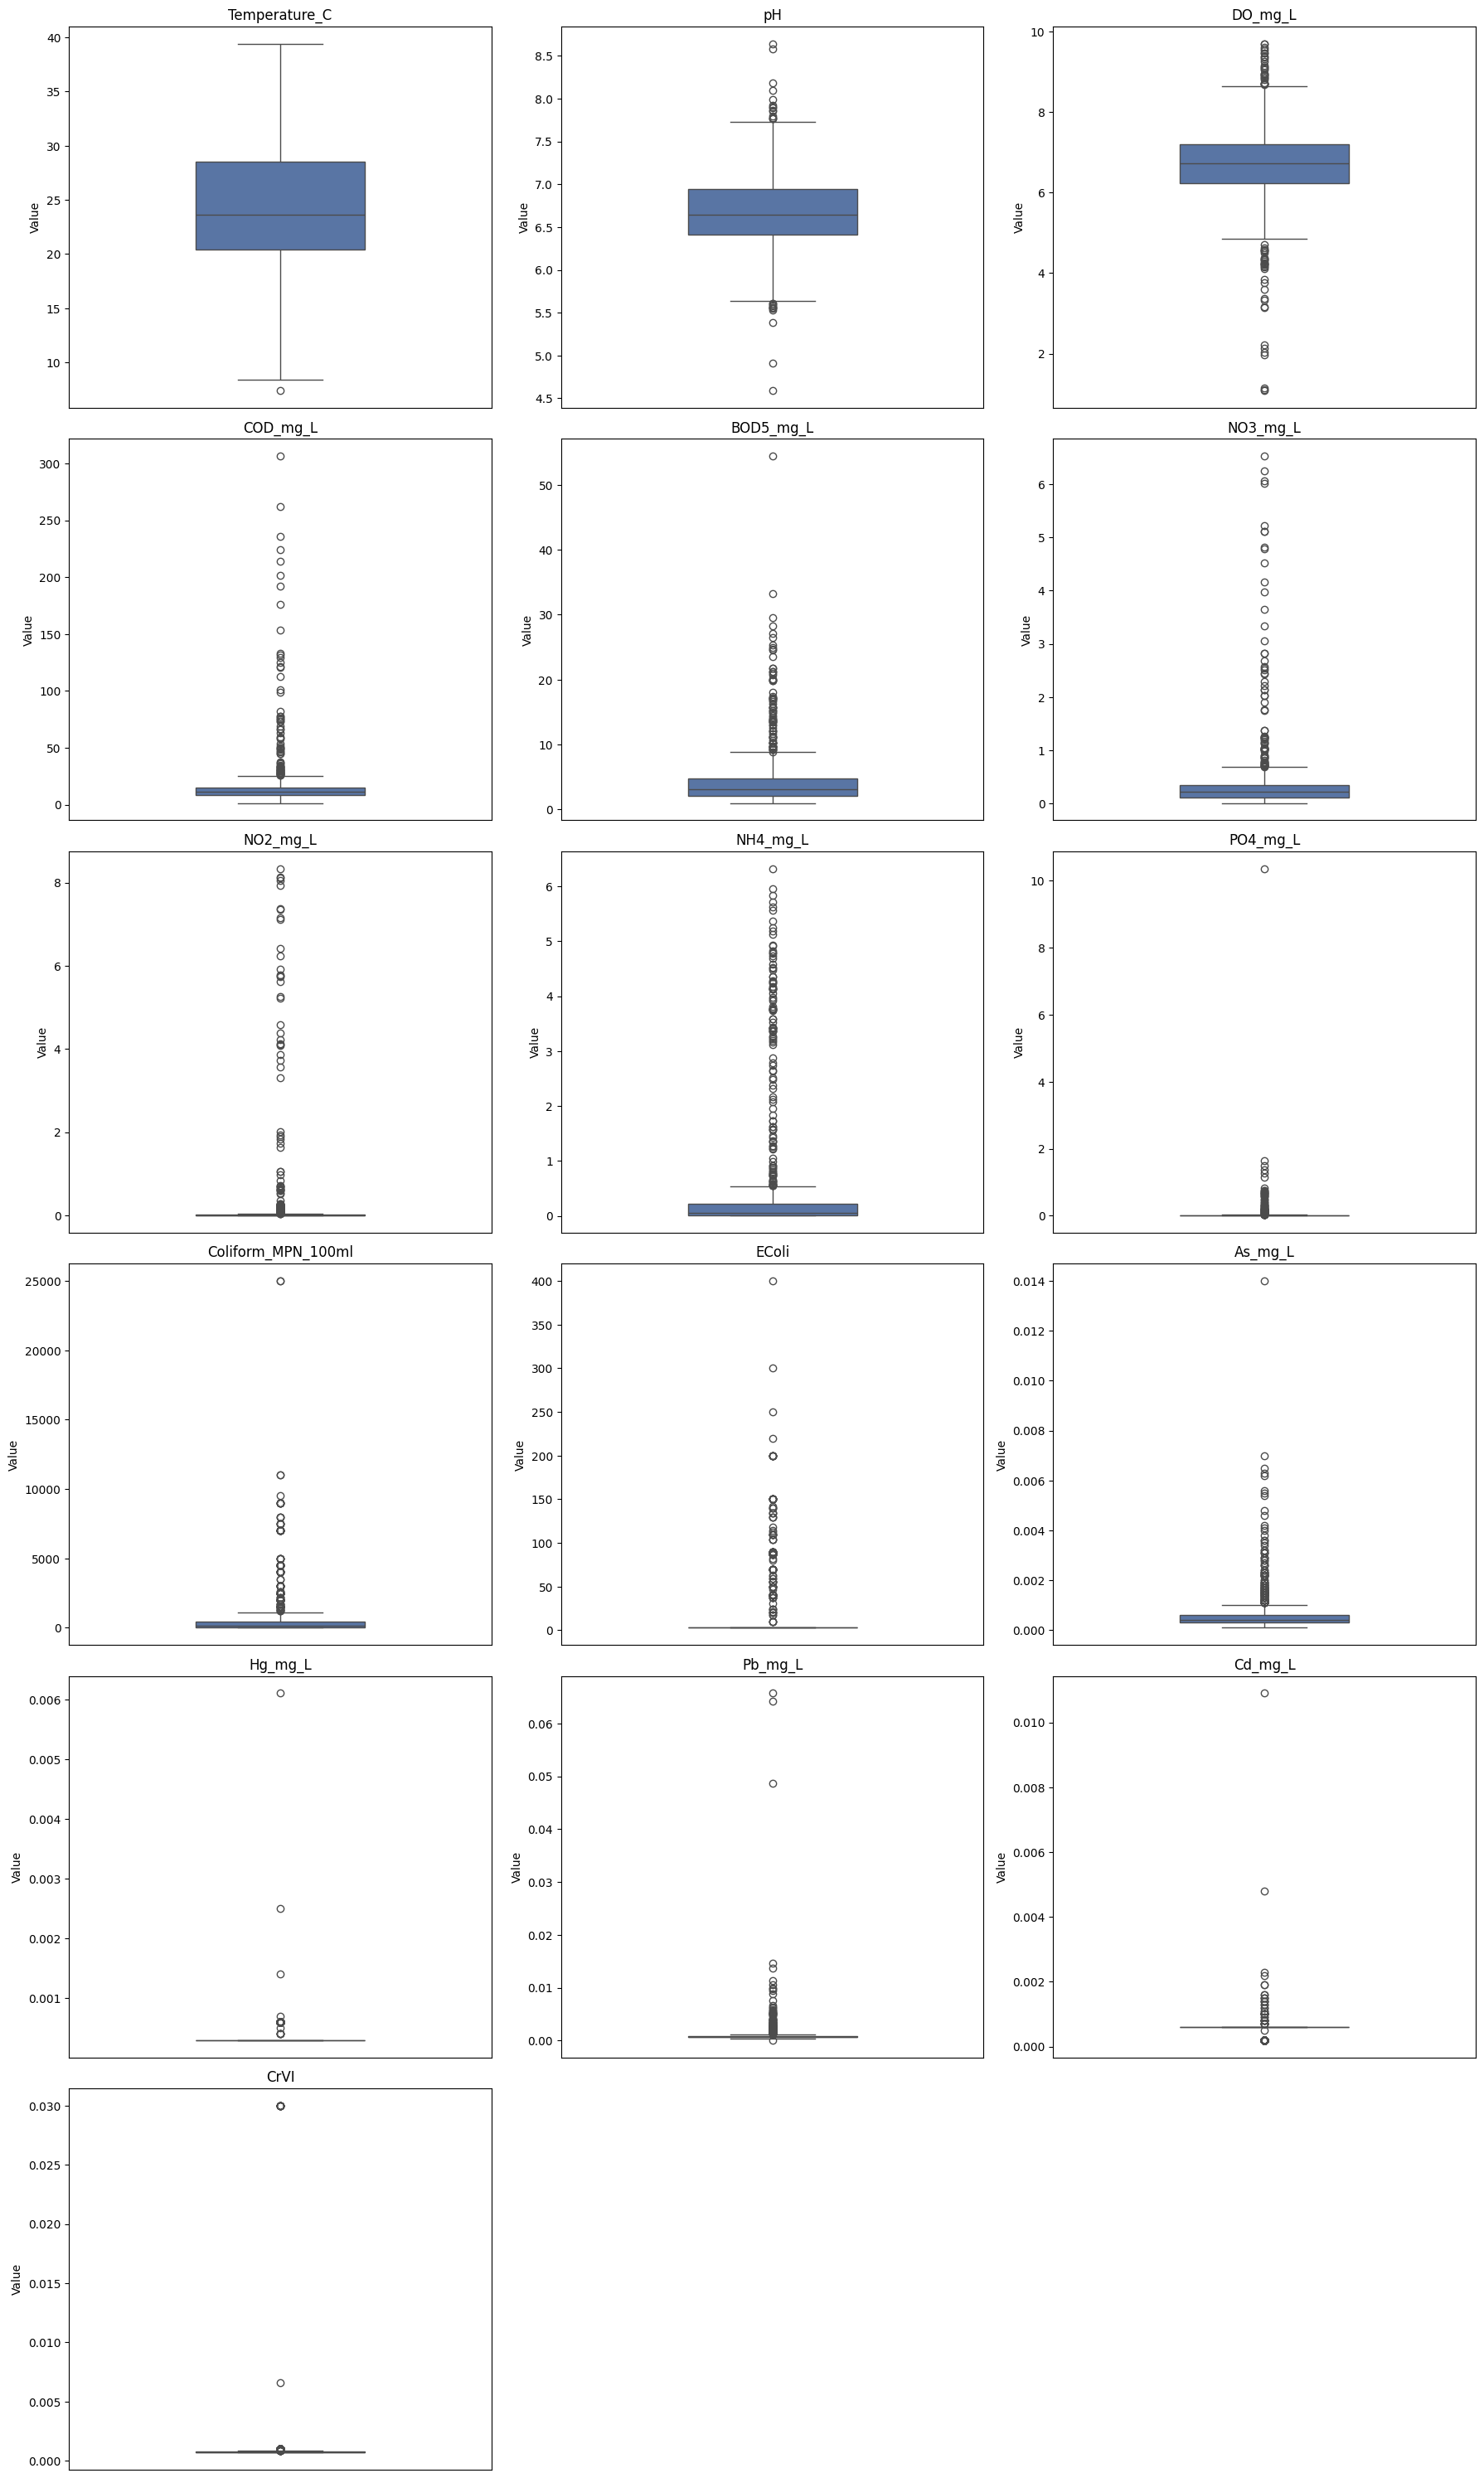

In [46]:
# Filter numeric columns
numeric_cols = wqi_data_convert_cell.select_dtypes(include='number').columns
n_cols = len(numeric_cols)

# Create a figure with a grid
n_rows = (n_cols // 3) + 1
plt.figure(figsize=(18, 5*n_rows))

for i, col in enumerate(numeric_cols):
    ax = plt.subplot(n_rows, 3, i+1)
    # Fix deprecated warning: add static x and legend=False
    sns.boxplot(x=[0]*len(wqi_data_convert_cell), y=wqi_data_convert_cell[col],
                ax=ax, palette=["#4c72b0"], width=0.4, dodge=False)
    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Value")
    ax.set_xticks([])  # ẩn nhãn trục x

plt.tight_layout()
plt.show()

## 1.3 Caculate the WQI output

In [47]:
# 1. Configure the BP threshold values for each metal
# The order of values corresponds to i = 1, 2, 3, 4, 5
metal_configs = {
    'As_mg_L':   [0.01, 0.02, 0.05, 0.1,  0.1], 
    'Cd_mg_L':   [0.005, 0.005, 0.008, 0.01, 0.1],
    'Pb_mg_L':   [0.02, 0.02, 0.04, 0.05, 0.5],
    'CrVI': [0.01, 0.02, 0.04, 0.05, 0.1],
    'Cu':   [0.1, 0.2, 0.5, 1.0, 2.0],
    'Zn':   [0.5, 1.0, 1.5, 2.0, 3.0],
    'Hg_mg_L':   [0.001, 0.001, 0.0015, 0.002, 0.01]
}

# q values corresponding to levels i from 1 to 5
q_values = [100, 75, 50, 25, 10]

# 2. General WQI calculation function
def calculate_wqi_generic(cp, bp_list):
    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # If Cp is better than or equal to the highest standard level (level 1)
    if cp <= bp_list[0]:
        return q_values[0]

    # If Cp is worse than or equal to the lowest standard level (level 5)
    if cp >= bp_list[4]:
        return q_values[4]

    # Find the interval to apply Formula 1
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i <= cp <= bp_i1:
            # Case when bp_i == bp_i1 (like Pb, Hg at levels 1-2)
            if cp == bp_i and i != 0:
                return cp
            if cp == bp_i1 and i != 4:
                return cp

            # Áp dụng Công thức 1
            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

# 3. Loop to automatically calculate for all columns in the configuration
for metal, bp_points in metal_configs.items():
    if metal in wqi_data_convert_cell.columns:
        new_col_name = f'WQI_{metal.split()[0]}' # Tạo tên cột như WQI_As, WQI_Cd...
        wqi_data_convert_cell[new_col_name] = wqi_data_convert_cell[metal].apply(
            lambda x: calculate_wqi_generic(x, bp_points)
        )

# Display the updated DataFrame with new WQI columns
print(wqi_data_convert_cell.head())

   Temperature_C    pH  DO_mg_L  COD_mg_L  BOD5_mg_L  NO3_mg_L  NO2_mg_L  \
0           21.5  7.90     8.23       9.8        4.5     0.747     0.064   
1           24.1  7.29     7.28      10.2        4.7     0.434     0.060   
2           28.4  6.81     7.18      19.2        7.2     0.492     0.002   
3           26.7  7.42     6.25      15.2        5.4     0.266     0.002   
4           17.1  6.31     7.44       5.3        1.8     0.865     0.023   

   NH4_mg_L  PO4_mg_L  Coliform_MPN_100ml  ...  As_mg_L  Hg_mg_L  Pb_mg_L  \
0     0.154     0.024               400.0  ...   0.0004   0.0003   0.0007   
1     0.215     0.010              2000.0  ...   0.0005   0.0003   0.0007   
2     0.232     0.057              4500.0  ...   0.0004   0.0003   0.0018   
3     0.522     0.098              7000.0  ...   0.0006   0.0003   0.0011   
4     0.096     0.048                40.0  ...   0.0003   0.0003   0.0001   

   Cd_mg_L     CrVI  WQI_As_mg_L  WQI_Cd_mg_L  WQI_Pb_mg_L  WQI_CrVI  \
0   0.00

In [48]:
def calculate_wqi_do(do_measured, temp):
    """
    Calculate the WQI for the DO parameter based on temperature and dissolved oxygen concentration.
    do_measured: Column 'DO mg/L'
    temp: Column 'Temperature (°C)'
    """
    if pd.isna(do_measured) or pd.isna(temp) or not isinstance(do_measured, (int, float)) or not isinstance(temp, (int, float)):
        return np.nan

    # Step 1: Calculate saturated DO (DO_saturated) based on temperature T
    # Formula: 14.652 - 0.41022*T + 0.0079910*T^2 - 0.0000777747*T^3
    do_sat = (14.652 - 0.41022 * temp +
              0.0079910 * (temp**2) -
              0.000077774 * (temp**3))

    # Calculate DO % saturation (Cp)
    cp = (do_measured / do_sat) * 100

    # Table 3: Standard values of BPi and qi for DO % saturation
    bp_do = [20, 50, 75, 88, 112, 125, 150, 200]
    q_do = [25, 50, 75, 100, 100, 75, 50, 25]

    # Check if Cp exactly matches any breakpoint values in the table
    for i, bp_val in enumerate(bp_do):
        if round(cp, 2) == bp_val:
            return q_do[i]

    if cp < 20 or cp > 200:
        return 10

    if 88 <= cp <= 112:
        return 100

    # Case 20 < Cp < 88: Use Formula 2
    if 20 < cp < 88:
        # Determine the interval i
        for i in range(0, 3): # Only consider breakpoints 20, 50, 75, 88
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Formula 2: WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
                wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
                return round(wqi, 2)

    # Case 112 < Cp < 200: Use Formula 1
    if 112 < cp < 200:
        # Determine the interval i (breakpoints 112, 125, 150, 200)
        for i in range(4, 7):
            bp_i, bp_i1 = bp_do[i], bp_do[i+1]
            q_i, q_i1 = q_do[i], q_do[i+1]

            if bp_i < cp < bp_i1:
                # Formula 1: WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
                wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
                return round(wqi, 2)


# Apply to DataFrame
wqi_data_convert_cell['WQI_DO'] = wqi_data_convert_cell.apply(
    lambda row: calculate_wqi_do(row['DO_mg_L'], row['Temperature_C']), axis=1
)

print(wqi_data_convert_cell[['DO_mg_L', 'Temperature_C', 'WQI_DO']].head())

   DO_mg_L  Temperature_C  WQI_DO
0     8.23           21.5  100.00
1     7.28           24.1   99.07
2     7.18           28.4  100.00
3     6.25           26.7   82.61
4     7.44           17.1   80.04


In [49]:
def calculate_wqi_ph(cp):
    """
    Calculate the WQI for the pH parameter based on Table 4 and interpolation formulas.
    cp: observed pH value.
    """

    if pd.isna(cp) or not isinstance(cp, (int, float)):
        return np.nan

    # Table 4: Regulations for BPi and qi values for pH
    # i=1: <5.5 (q=10), i=2: 5.5 (q=50), i=3: 6 (q=100)
    # i=4: 8.5 (q=100), i=5: 9 (q=50), i=6: >9 (q=10)

    # 1. Case when the value is outside the range or exactly at an extreme boundary
    if cp < 5.5 or cp > 9:
        return 10


    # 2. Case when the value exactly matches the breakpoint values in the table
    if cp == 5.5: return 50
    if cp == 6.0: return 100
    if cp == 8.5: return 100
    if cp == 9.0: return 50

    # 3. Case when 5.5 < pH < 6: Use Formula 2
    if 5.5 < cp < 6:
        # i=2 (BPi=5.5, qi=50); i+1=3 (BPi+1=6, qi+1=100)
        bp_i, bp_i1 = 5.5, 6.0
        q_i, q_i1 = 50, 100
        # WQI = [(qi+1 - qi) / (BPi+1 - BPi)] * (Cp - BPi) + qi
        wqi = ((q_i1 - q_i) / (bp_i1 - bp_i)) * (cp - bp_i) + q_i
        return round(wqi, 2)

    # 4. Case when 6 <= pH <= 8.5: WQI = 100
    if 6 <= cp <= 8.5:
        return 100

    # 5. Case when 8.5 < pH < 9: Use Formula 1
    if 8.5 < cp < 9:
        # i=4 (BPi=8.5, qi=100); i+1=5 (BPi+1=9, qi+1=50)
        bp_i, bp_i1 = 8.5, 9.0
        q_i, q_i1 = 100, 50
        # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
        wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
        return round(wqi, 2)

# Apply to the entire data in the 'pH' column
wqi_data_convert_cell['WQI_ph'] = wqi_data_convert_cell['pH'].apply(calculate_wqi_ph)

# Display the check results
print(wqi_data_convert_cell[['pH', 'WQI_ph']].head())

     pH  WQI_ph
0  7.90   100.0
1  7.29   100.0
2  6.81   100.0
3  7.42   100.0
4  6.31   100.0


In [50]:
# 1. Set up the BP benchmark values table for each parameter
# Corresponding q values order: 100, 75, 50, 25, 10
q_values = [100, 75, 50, 25, 10]

params_config = {
    'BOD5_mg_L':          [4, 6, 15, 25, 50],
    'COD_mg_L':           [10, 15, 30, 50, 150],
    'TOC':                [4, 6, 15, 25, 50],
    'NH4_mg_L':          [0.3, 0.3, 0.6, 0.9, 5], 
    'NO3_mg_L':           [2, 5, 10, 15, 15],  
    'PO4_mg_L':         [0.1, 0.2, 0.3, 0.5, 4],
    'Coliform_MPN_100ml': [2500, 5000, 7500, 10000, 10000],
    'EColi':             [20, 50, 100, 200, 200]
}

# 2. General function to calculate WQI SI (using Formula 1)
def calculate_wqi_formula1(cp, bp_list):
    if pd.isna(cp): return np.nan

    # Case when the value matches a boundary or exceeds an extreme limit
    if cp <= bp_list[0]: return q_values[0]
    if cp >= bp_list[4]: return q_values[4]

    # Check if the Cp value exactly matches the BPi benchmark point
    for i, bp_val in enumerate(bp_list):
        if cp == bp_val:
            return q_values[i]

    # Apply Formula 1 for the intervals
    for i in range(len(bp_list) - 1):
        bp_i, bp_i1 = bp_list[i], bp_list[i+1]
        q_i, q_i1 = q_values[i], q_values[i+1]

        if bp_i < cp < bp_i1:
            # WQI = [(qi - qi+1) / (BPi+1 - BPi)] * (BPi+1 - Cp) + qi+1
            wqi = ((q_i - q_i1) / (bp_i1 - bp_i)) * (bp_i1 - cp) + q_i1
            return round(wqi, 2)

# 3. Loop automatically to calculate for columns (Except NO2- handled separately)
for param, bp_points in params_config.items():
    if param in wqi_data_convert_cell.columns:
        # Create a new column name, e.g., WQI_BOD5, WQI_NH4...
        new_col = f"WQI_{param.replace('+', '').replace('-', '')}"
        wqi_data_convert_cell[new_col] = wqi_data_convert_cell[param].apply(
            lambda x: calculate_wqi_formula1(x, bp_points)
        )

# 4. Handle NO2- separately (Because the table only has 2 levels: <=0.05 and >0.05)
if 'NO2_mg_L' in wqi_data_convert_cell.columns:
    wqi_data_convert_cell['WQI_NO2_mg_L'] = wqi_data_convert_cell['NO2_mg_L'].apply(
        lambda x: 100 if x <= 0.05 else 10 if x > 0.05 else np.nan
    )

# Display the results of the newly created WQI columns
wqi_cols = [c for c in wqi_data_convert_cell.columns if c.startswith('WQI_')]
print(wqi_data_convert_cell[wqi_cols].head())

   WQI_As_mg_L  WQI_Cd_mg_L  WQI_Pb_mg_L  WQI_CrVI  WQI_Hg_mg_L  WQI_DO  \
0        100.0        100.0        100.0     100.0        100.0  100.00   
1        100.0        100.0        100.0     100.0        100.0   99.07   
2        100.0        100.0        100.0     100.0        100.0  100.00   
3        100.0        100.0        100.0     100.0        100.0   82.61   
4        100.0        100.0        100.0     100.0        100.0   80.04   

   WQI_ph  WQI_BOD5_mg_L  WQI_COD_mg_L  WQI_NH4_mg_L  WQI_NO3_mg_L  \
0   100.0          93.75        100.00         100.0         100.0   
1   100.0          91.25         99.00         100.0         100.0   
2   100.0          71.67         68.00         100.0         100.0   
3   100.0          82.50         74.67          56.5         100.0   
4   100.0         100.00        100.00         100.0         100.0   

   WQI_PO4_mg_L  WQI_Coliform_MPN_100ml  WQI_EColi  WQI_NO2_mg_L  
0         100.0                   100.0     100.00           

In [51]:
wqi_data_convert_cell.isnull().sum()

Temperature_C             0
pH                        0
DO_mg_L                   0
COD_mg_L                  0
BOD5_mg_L                 0
NO3_mg_L                  0
NO2_mg_L                  0
NH4_mg_L                  0
PO4_mg_L                  0
Coliform_MPN_100ml        0
EColi                     0
As_mg_L                   0
Hg_mg_L                   0
Pb_mg_L                   0
Cd_mg_L                   0
CrVI                      0
WQI_As_mg_L               0
WQI_Cd_mg_L               0
WQI_Pb_mg_L               0
WQI_CrVI                  0
WQI_Hg_mg_L               0
WQI_DO                    0
WQI_ph                    0
WQI_BOD5_mg_L             0
WQI_COD_mg_L              0
WQI_NH4_mg_L              0
WQI_NO3_mg_L              0
WQI_PO4_mg_L              0
WQI_Coliform_MPN_100ml    0
WQI_EColi                 0
WQI_NO2_mg_L              0
dtype: int64

In [52]:
def calculate_final_vn_wqi(row):
    # 1. Grouping of parameters
    group_i_cols = ['WQI_ph']

    # Group II: Pesticides
    group_ii_cols = [col for col in row.index if col.startswith('WQI_') and
                     any(p in col for p in ['Aldrin', 'DDTs', 'BHC', 'Dieldrin'])]

    # Group III: Heavy metals
    group_iii_cols = ['WQI_As_mg_L', 'WQI_Cd_mg_L', 'WQI_Pb_mg_L', 'WQI_CrVI', 'WQI_Cu', 'WQI_Zn', 'WQI_Hg_mg_L']

    # Group IV: Organic & Nutrients (Mandatory - at least 3 parameters)
    group_iv_cols = ['WQI_DO', 'WQI_BOD5_mg_L', 'WQI_COD_mg_L', 'WQI_TOC', 'NH4_mg_L', 'NO3_mg_L', 'WQI_NO2_mg_L', 'WQI_PO4_mg_L']

    # Group V: Microbiological
    group_v_cols = ['WQI_Coliform_MPN_100ml', 'WQI_EColi']

    # 2. Check calculation conditions
    # - Group IV is mandatory and must have at least 3 parameters
    valid_iv = [row[c] for c in group_iv_cols if c in row.index and pd.notna(row[c])]
    if len(valid_iv) < 3:
        return np.nan # Not enough conditions to calculate VN_WQI
    # - At least 3 out of 5 parameter groups must be available 
    available_groups = 0
    groups_data = {}

    for g_name, cols in [('I', group_i_cols), ('II', group_ii_cols),
                         ('III', group_iii_cols), ('IV', group_iv_cols), ('V', group_v_cols)]:
        valid_vals = [row[c] for c in cols if c in row.index and pd.notna(row[c])]
        if valid_vals:
            available_groups += 1
            groups_data[g_name] = valid_vals

    if available_groups < 3:
        return np.nan

    # 3. Calculate the average value for each group
    # Group I: WQI_I
    wqi_1 = groups_data['I'][0] if 'I' in groups_data else 100

    # Group II & III: Geometric Mean
    wqi_2_val = gmean(groups_data['II']) if 'II' in groups_data else 100
    wqi_3_val = gmean(groups_data['III']) if 'III' in groups_data else 100

    # Group IV & V: Arithmetic Mean
    wqi_4_avg = np.mean(groups_data['IV'])
    wqi_5_avg = np.mean(groups_data['V']) if 'V' in groups_data else np.nan

    # 4. Apply Formula 3
    # Square root component of groups IV and V
    if not np.isnan(wqi_5_avg):
        bracket_term = np.sqrt(wqi_4_avg * wqi_5_avg)
    else:
        bracket_term = wqi_4_avg # If group V is missing, use only group IV
    final_wqi = (wqi_1 / 100) * (wqi_2_val / 100) * (wqi_3_val / 100) * bracket_term

    return round(final_wqi, 0)

# Apply calculation to the entire DataFrame
wqi_data_convert_cell['VN_WQI'] = wqi_data_convert_cell.apply(calculate_final_vn_wqi, axis=1)

# Display the final results
print(wqi_data_convert_cell[['VN_WQI']].head())

   VN_WQI
0    76.0
1    71.0
2    69.0
3    56.0
4    83.0


In [53]:
wqi_data_convert_cell.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1101 entries, 0 to 1109
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature_C           1101 non-null   float64
 1   pH                      1101 non-null   float64
 2   DO_mg_L                 1101 non-null   float64
 3   COD_mg_L                1101 non-null   float64
 4   BOD5_mg_L               1101 non-null   float64
 5   NO3_mg_L                1101 non-null   float64
 6   NO2_mg_L                1101 non-null   float64
 7   NH4_mg_L                1101 non-null   float64
 8   PO4_mg_L                1101 non-null   float64
 9   Coliform_MPN_100ml      1101 non-null   float64
 10  EColi                   1101 non-null   float64
 11  As_mg_L                 1101 non-null   float64
 12  Hg_mg_L                 1101 non-null   float64
 13  Pb_mg_L                 1101 non-null   float64
 14  Cd_mg_L                 1101 non-null   float

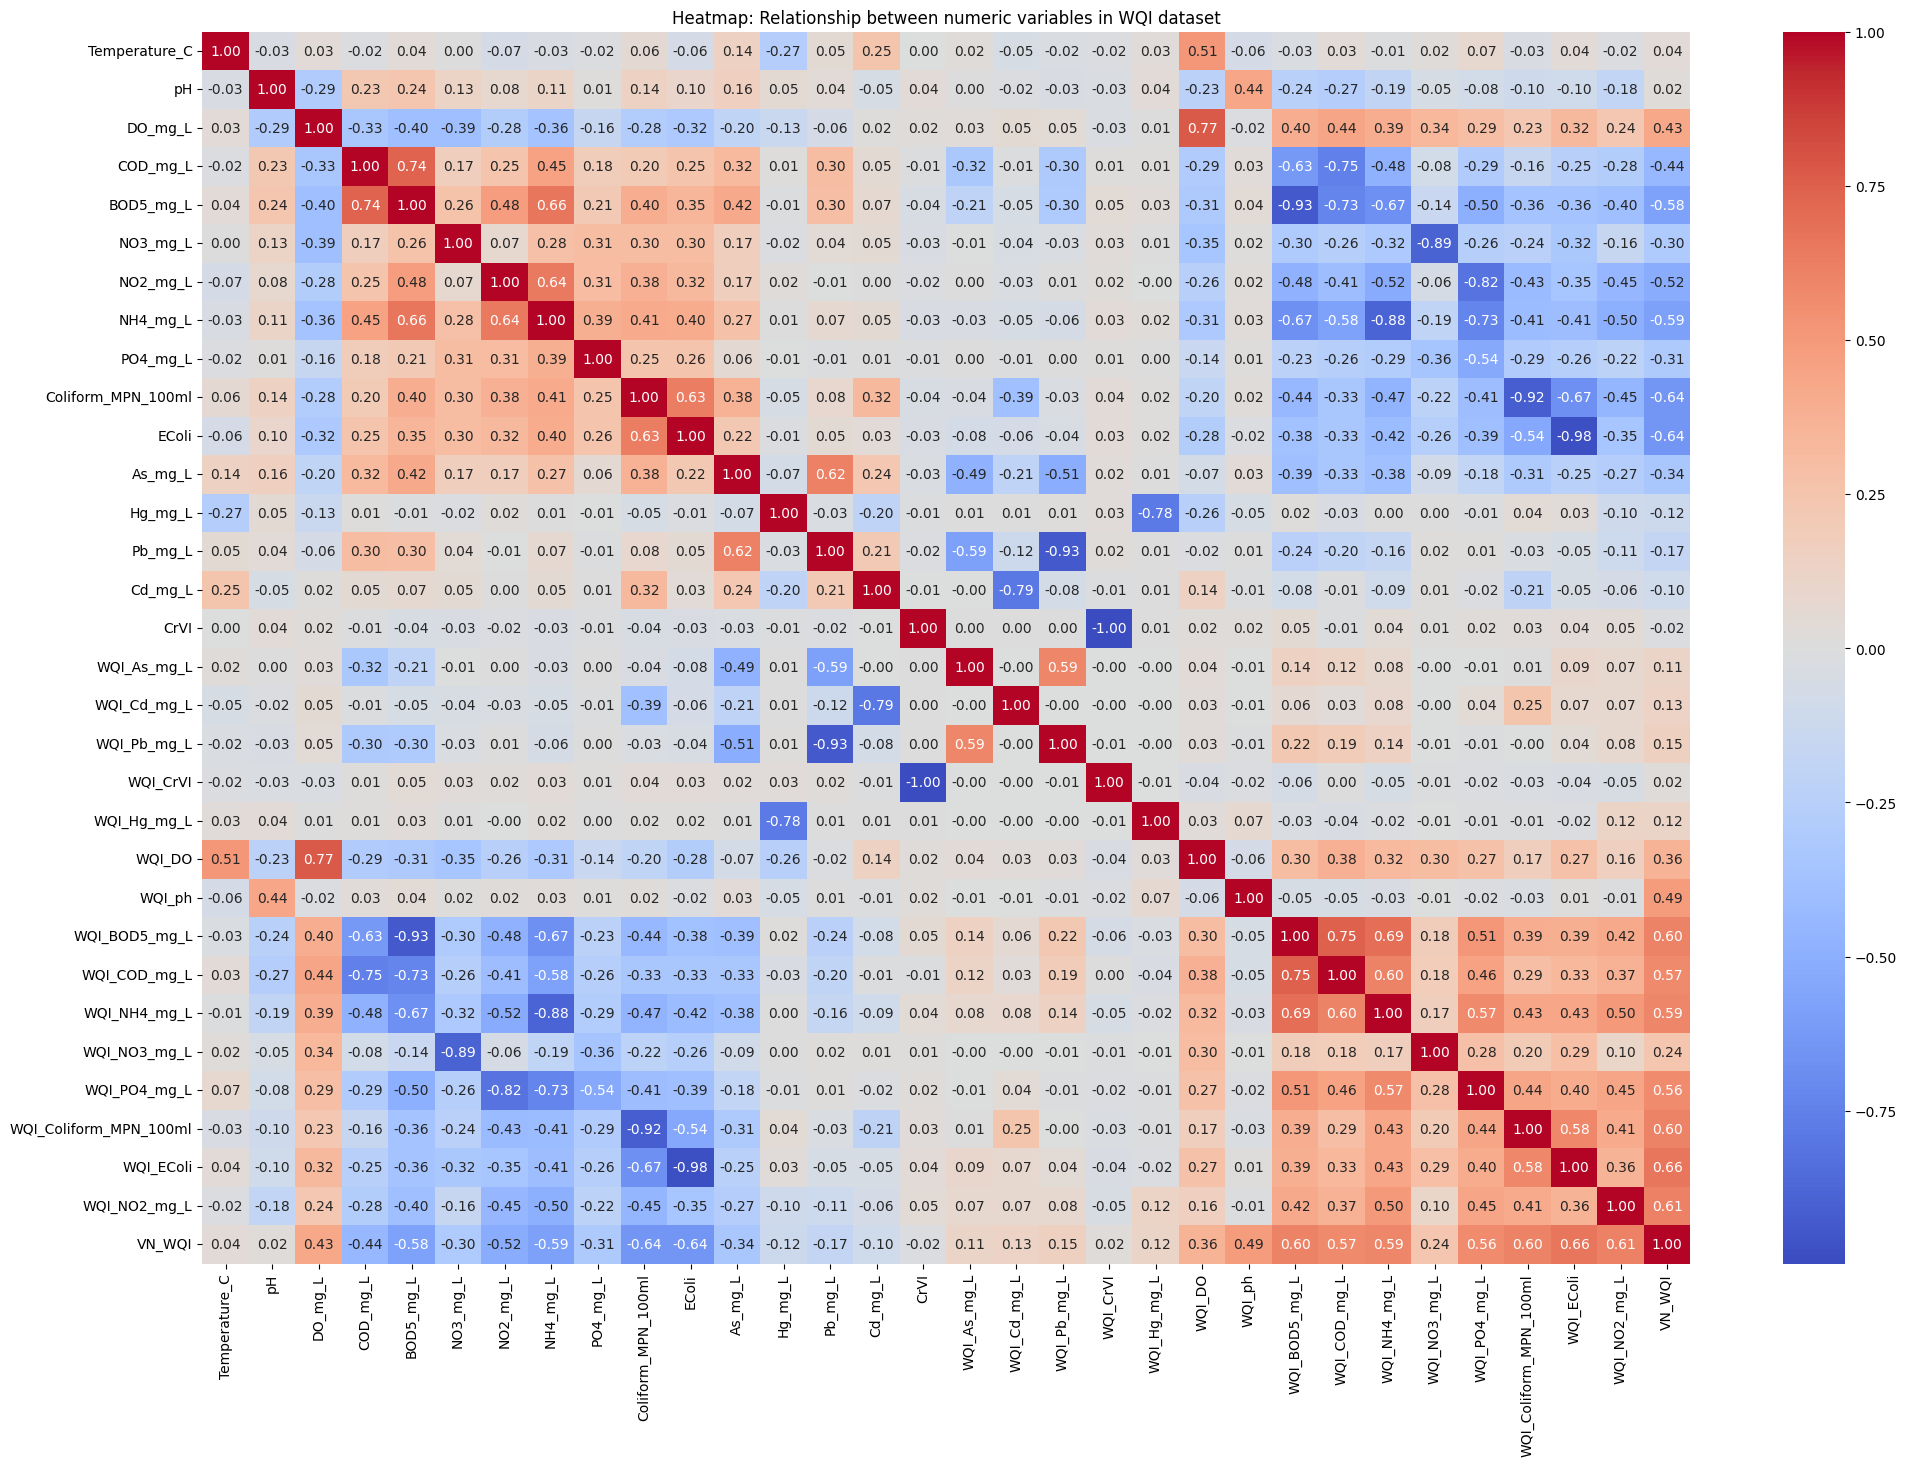

In [54]:
# Get numeric columns
numeric_cols = wqi_data_convert_cell.select_dtypes(include=['int64', 'float64']).columns
df_numeric = wqi_data_convert_cell[numeric_cols]

# Calculate correlation matrix
corr_matrix = df_numeric.corr()

plt.figure(figsize=(24, 16))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Heatmap: Relationship between numeric variables in WQI dataset")
plt.show()


In [55]:
# Chỉ lấy các cột số (numeric features)
numeric_df = final_data.select_dtypes(include='number')

# Tạo bảng thống kê
stats_table = pd.DataFrame({
    'Mean': numeric_df.mean(),
    'Minimum': numeric_df.min(),
    'Maximum': numeric_df.max(),
    'Standard Deviation': numeric_df.std(),
    'Variance': numeric_df.var(),
    'Range': numeric_df.max() - numeric_df.min()
})

stats_table = stats_table.round(3)
stats_table.style.format("{:.3f}") \
    .set_caption("Descriptive Statistics of Water Quality Parameters") \
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size', '14px'), ('font-weight', 'bold')]},
        {'selector': 'th',
         'props': [('background-color', "#000000"),
                   ('font-weight', 'bold'),
                   ('text-align', 'center')]},
        {'selector': 'td',
         'props': [('text-align', 'center')]}
    ])

NameError: name 'final_data' is not defined

In [ ]:
final_data = wqi_data_convert_cell.drop(columns=['WQI_As_mg_L', 'WQI_Cd_mg_L', 'WQI_Pb_mg_L', 'WQI_CrVI', 'WQI_Hg_mg_L', 'WQI_DO', 'WQI_ph', 'WQI_BOD5_mg_L', 'WQI_COD_mg_L', 'WQI_NH4_mg_L', 'WQI_NO3_mg_L', 'WQI_PO4_mg_L', 'WQI_Coliform_MPN_100ml', 'WQI_EColi', 'WQI_NO2_mg_L'])

# 2. Exploratory Data Analysis


---

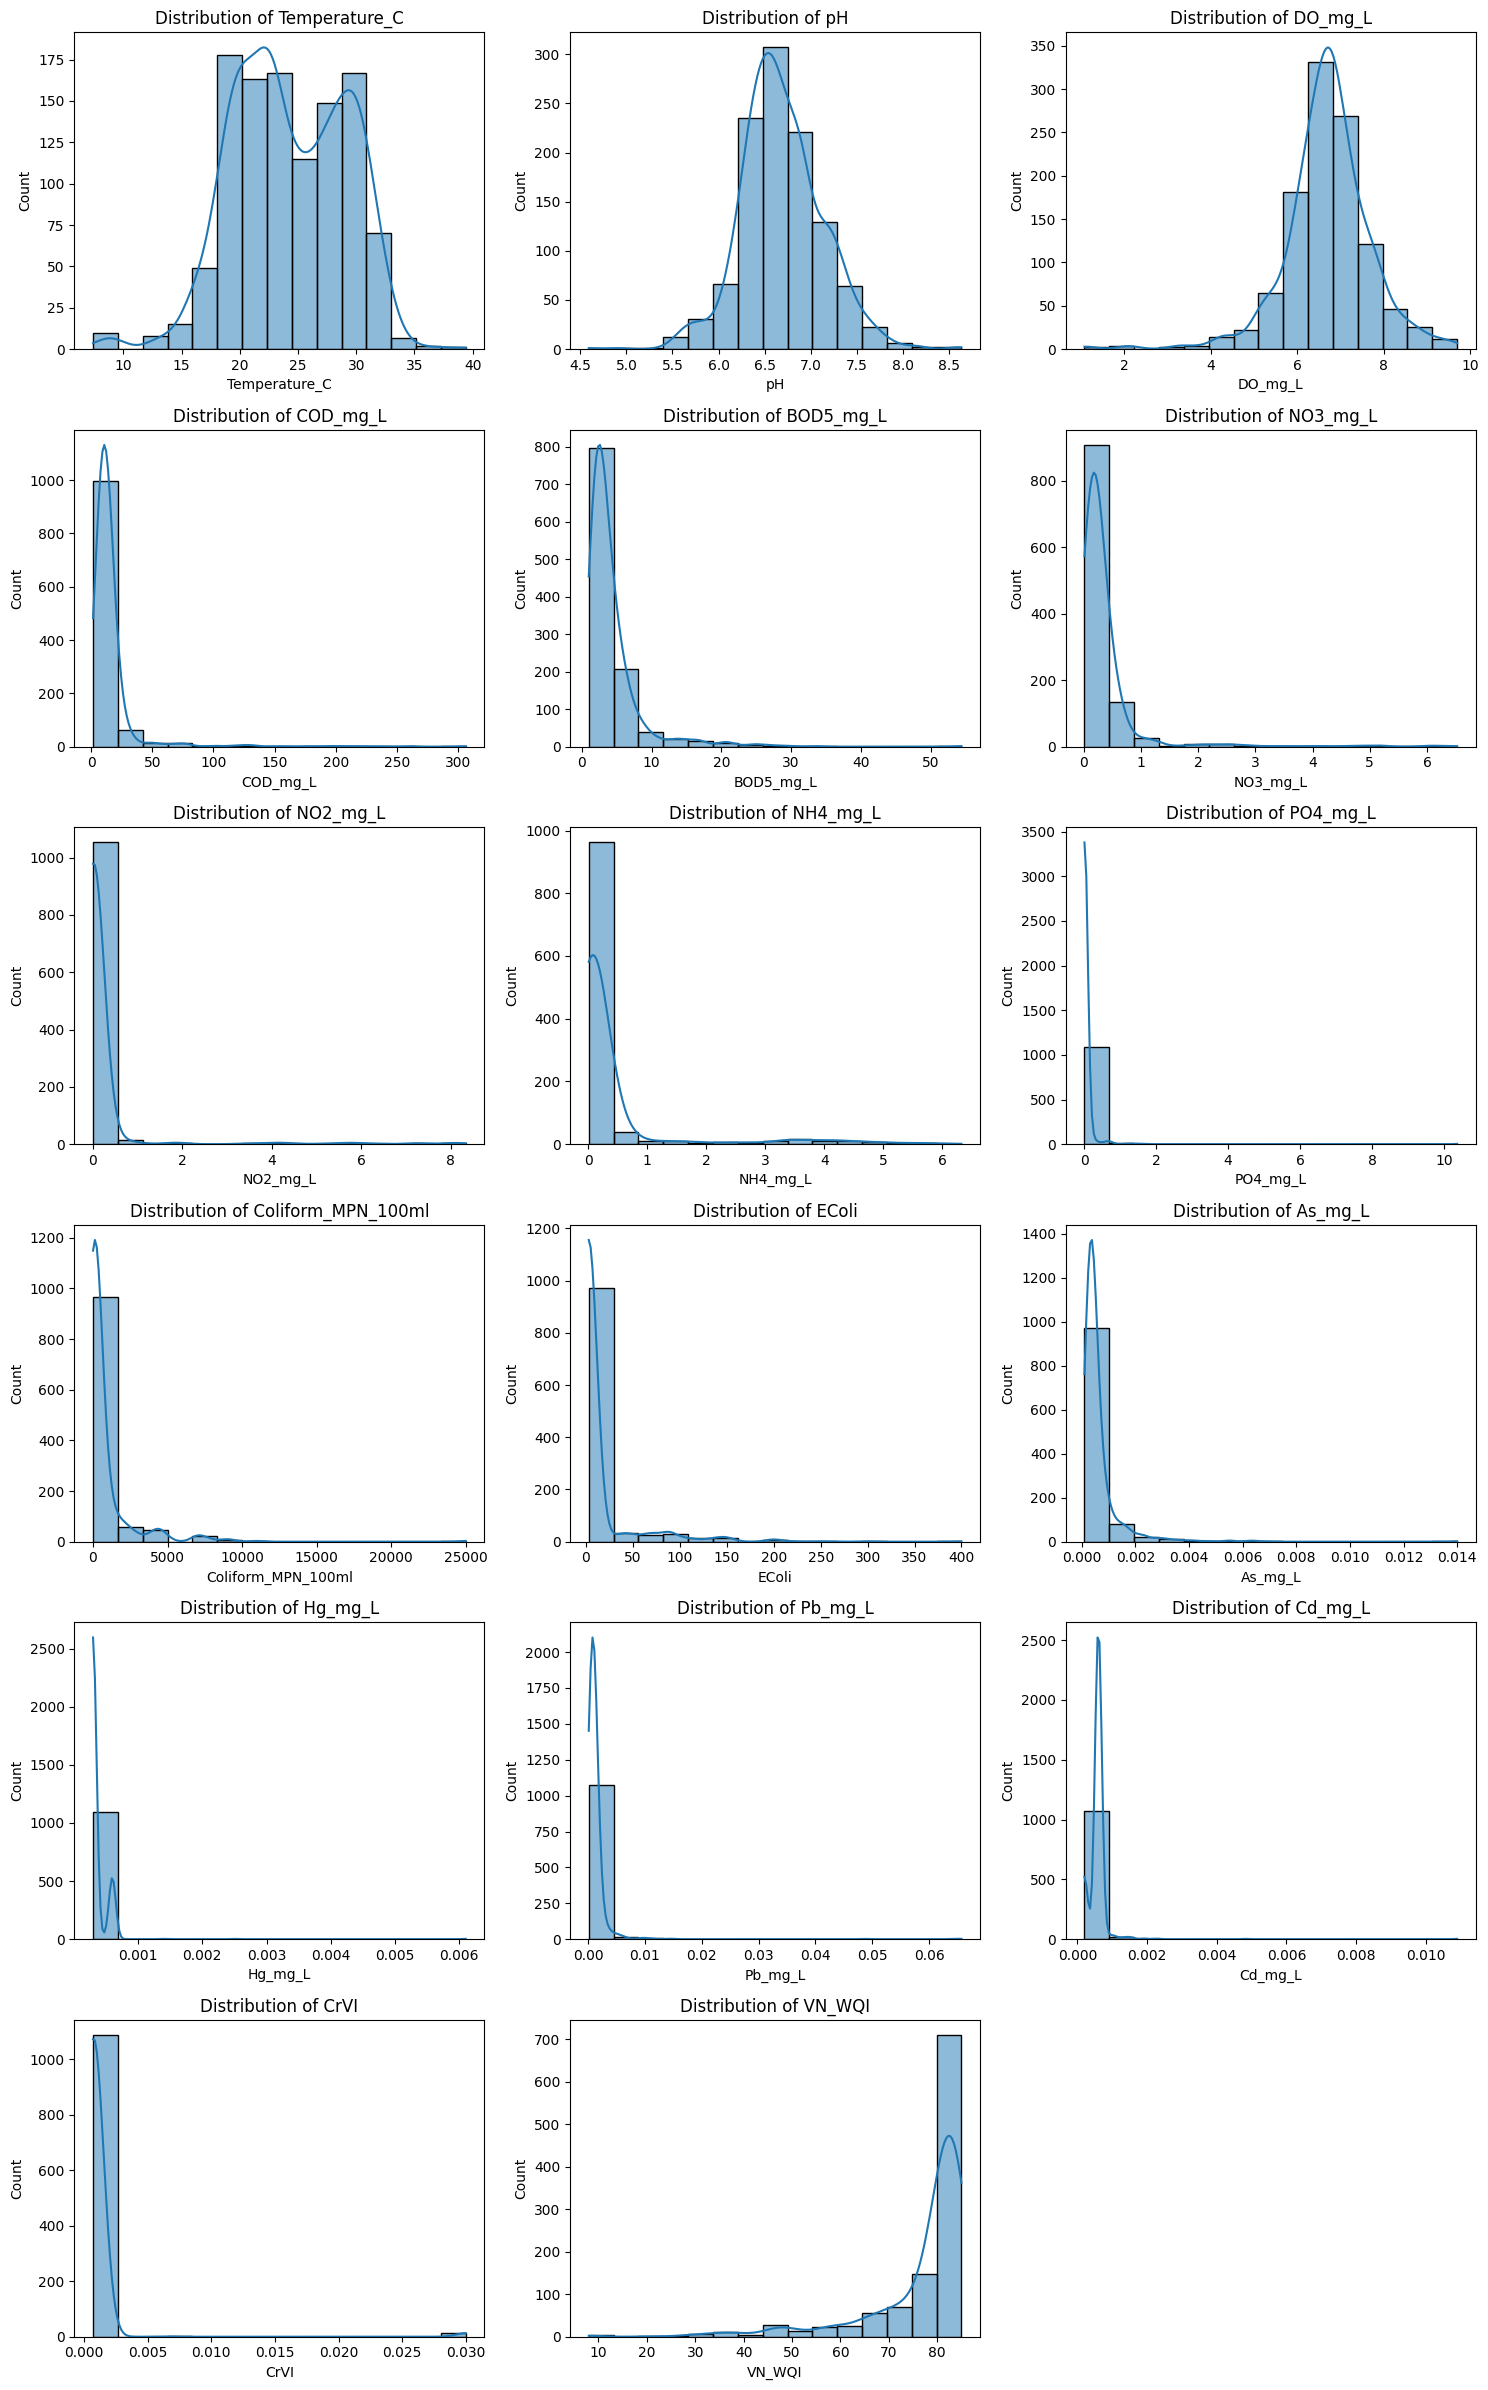

In [ ]:
numeric_cols = final_data.select_dtypes(include=['int64', 'float64']).columns

# Plot histograms for numeric columns
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

plt.figure(figsize=(5 * n_cols, 4 * n_rows))

for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(final_data[col], bins=15, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

# 3. Feature Engineering


---

In [ ]:
class LRWrapper(LinReg := LinearRegression):
    def __init__(self, degree=1, **kwargs):
        super().__init__(**kwargs)
        self.degree = degree

    def fit(self, X, y):
        # Create scaler and polynomial features transformer
        self.scaler_ = RobustScaler()
        self.poly_ = PolynomialFeatures(degree=self.degree, interaction_only=True, include_bias=False)

        # Scale and transform
        X_scaled = self.scaler_.fit_transform(X)
        X_poly = self.poly_.fit_transform(X_scaled)

        # Call fit of LinearRegression
        super().fit(X_poly, y)
        return self

    def predict(self, X):
        X_scaled = self.scaler_.transform(X)
        X_poly = self.poly_.transform(X_scaled)
        return super().predict(X_poly)

In [ ]:

knn_model = Pipeline([
    ('scaler', RobustScaler()),
    ('knn', KNeighborsRegressor(
        n_neighbors=7,
        weights='distance',   # rất nên dùng cho dữ liệu nhiều outlier
        metric='minkowski'
    ))
])

In [ ]:
svr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR(kernel='rbf', C=10, epsilon=0.1))
])

# 4. Classifier Training


---

## 4.1. Data Splitting

In [ ]:
final_data.shape

(1101, 17)

In [ ]:
# Separate X and y
X = final_data[['Temperature_C', 'pH', 'DO_mg_L', 'COD_mg_L', 'BOD5_mg_L', 
                'NO3_mg_L', 'NO2_mg_L', 'NH4_mg_L', 'PO4_mg_L', 
                'Coliform_MPN_100ml', 'EColi', 'As_mg_L', 'Hg_mg_L', 'Pb_mg_L', 
                'Cd_mg_L', 'CrVI']]  # Features
y = final_data['VN_WQI']  # WQI index

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 4.2. Model Training

In [ ]:
# Define the parameter grid for RandomForest
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_split': [5, 10, 15]
}

# Initialize GridSearchCV for RandomForest
rf_grid_search = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=5, n_jobs=-1)
rf_grid_search.fit(X_train, y_train)

# Get the best hyperparameters from GridSearchCV
best_rf_params = rf_grid_search.best_params_
print("Best parameters for RandomForest:", best_rf_params)

Best parameters for RandomForest: {'max_depth': 30, 'min_samples_split': 5, 'n_estimators': 200}


In [ ]:
# Define the parameter grid for GradientBoosting
gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# Initialize GridSearchCV for GradientBoosting
gb_grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_param_grid, cv=5, n_jobs=-1)
gb_grid_search.fit(X_train, y_train)

# Get the best hyperparameters from GridSearchCV
best_gb_params = gb_grid_search.best_params_
print("Best parameters for GradientBoosting:", best_gb_params)

Best parameters for GradientBoosting: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}


In [ ]:
!pip install quantile-forest

In [ ]:
# Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Linear Regression model
lr_model = LRWrapper()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# KNN model
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

# SVR model
svr_model.fit(X_train, y_train)
svr_pred = svr_model.predict(X_test)

NameError: name 'X_train' is not defined

In [ ]:
print("Random Forest - MSE:", mean_squared_error(y_test, rf_pred))
print("Random Forest - RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("Random Forest - MAE:", mean_absolute_error(y_test, rf_pred))
print("Random Forest - R^2:", r2_score(y_test, rf_pred))

print("\n" + "="*50 + "\n")

print("Linear Regression - MSE:", mean_squared_error(y_test, lr_pred))
print("Linear Regression - RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("Linear Regression - MAE:", mean_absolute_error(y_test, lr_pred))
print("Linear Regression - R^2:", r2_score(y_test, lr_pred))

print("\n" + "="*50 + "\n")

print("K-Nearest Neighbors - MSE:", mean_squared_error(y_test, knn_pred))
print("K-Nearest Neighbors - RMSE:", np.sqrt(mean_squared_error(y_test, knn_pred)))
print("K-Nearest Neighbors - MAE:", mean_absolute_error(y_test, knn_pred))
print("K-Nearest Neighbors - R^2:", r2_score(y_test, knn_pred))

print("\n" + "="*50 + "\n")

print("Support Vector Regression - MSE:", mean_squared_error(y_test, svr_pred))
print("Support Vector Regression - RMSE:", np.sqrt(mean_squared_error(y_test, svr_pred)))
print("Support Vector Regression - MAE:", mean_absolute_error(y_test, svr_pred))
print("Support Vector Regression - R^2:", r2_score(y_test, svr_pred))

Random Forest - MSE: 4.880405429864253
Random Forest - RMSE: 2.2091639662696503
Random Forest - MAE: 1.0622624434389136
Random Forest - R^2: 0.9583852784471166


Linear Regression - MSE: 27.148880478706477
Linear Regression - RMSE: 5.21045875894882
Linear Regression - MAE: 3.5168822774550996
Linear Regression - R^2: 0.7685042528064508


K-Nearest Neighbors - MSE: 17.635378678099123
K-Nearest Neighbors - RMSE: 4.199449806593612
K-Nearest Neighbors - MAE: 2.086523050725447
K-Nearest Neighbors - R^2: 0.8496249166764075


Support Vector Regression - MSE: 24.058018188945155
Support Vector Regression - RMSE: 4.904897367829948
Support Vector Regression - MAE: 2.7105813615005054
Support Vector Regression - R^2: 0.7948597217106609


In [ ]:
# Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Gradient Boosting model
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

In [ ]:
print("Random Forest - MSE:", mean_squared_error(y_test, rf_pred))
print("Random Forest - RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("Random Forest - MAE:", mean_absolute_error(y_test, rf_pred))
print("Random Forest - R^2:", r2_score(y_test, rf_pred))

print("\n" + "="*50 + "\n")

print("Gradient Boosting - MSE:", mean_squared_error(y_test, gb_pred))
print("Gradient Boosting - RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("Gradient Boosting - MAE:", mean_absolute_error(y_test, gb_pred))
print("Gradient Boosting - R^2:", r2_score(y_test, gb_pred))

Random Forest - MSE: 4.880405429864253
Random Forest - RMSE: 2.2091639662696503
Random Forest - MAE: 1.0622624434389136
Random Forest - R^2: 0.9583852784471166


Gradient Boosting - MSE: 4.377694781065906
Gradient Boosting - RMSE: 2.092294143055872
Gradient Boosting - MAE: 1.0179496149880312
Gradient Boosting - R^2: 0.9626718411050872


In [ ]:
# Optimized base models
optimized_models = {
    'RandomForest': RandomForestRegressor(**best_rf_params),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, verbosity=0),
    'GradientBoosting': GradientBoostingRegressor(**best_gb_params)
}

# Meta-model - this is the model for learning the ensemble
#meta_model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, verbosity=0)
meta_model = LRWrapper(degree=2)

# Create the StackingRegressor with base models and the meta-model
stacking_model = StackingRegressor(
    estimators=[('rf', optimized_models['RandomForest']),
                ('xgb', optimized_models['XGBoost']),
                ('gb', optimized_models['GradientBoosting'])],
    final_estimator=meta_model
)

# Train the stacking model on the training data (X_train and y_train)
stacking_model.fit(X_train, y_train)
sm_pred = stacking_model.predict(X_test)

In [ ]:
print("Stacking Model - MSE:", mean_squared_error(y_test, sm_pred))
print("Stacking Model - RMSE:", np.sqrt(mean_squared_error(y_test, sm_pred)))
print("Stacking Model - MAE:", mean_absolute_error(y_test, sm_pred))
print("Stacking Model - R^2:", r2_score(y_test, sm_pred))

Stacking Model - MSE: 4.1689283739621255
Stacking Model - RMSE: 2.041795380042311
Stacking Model - MAE: 0.9326867382473503
Stacking Model - R^2: 0.9644519710606965


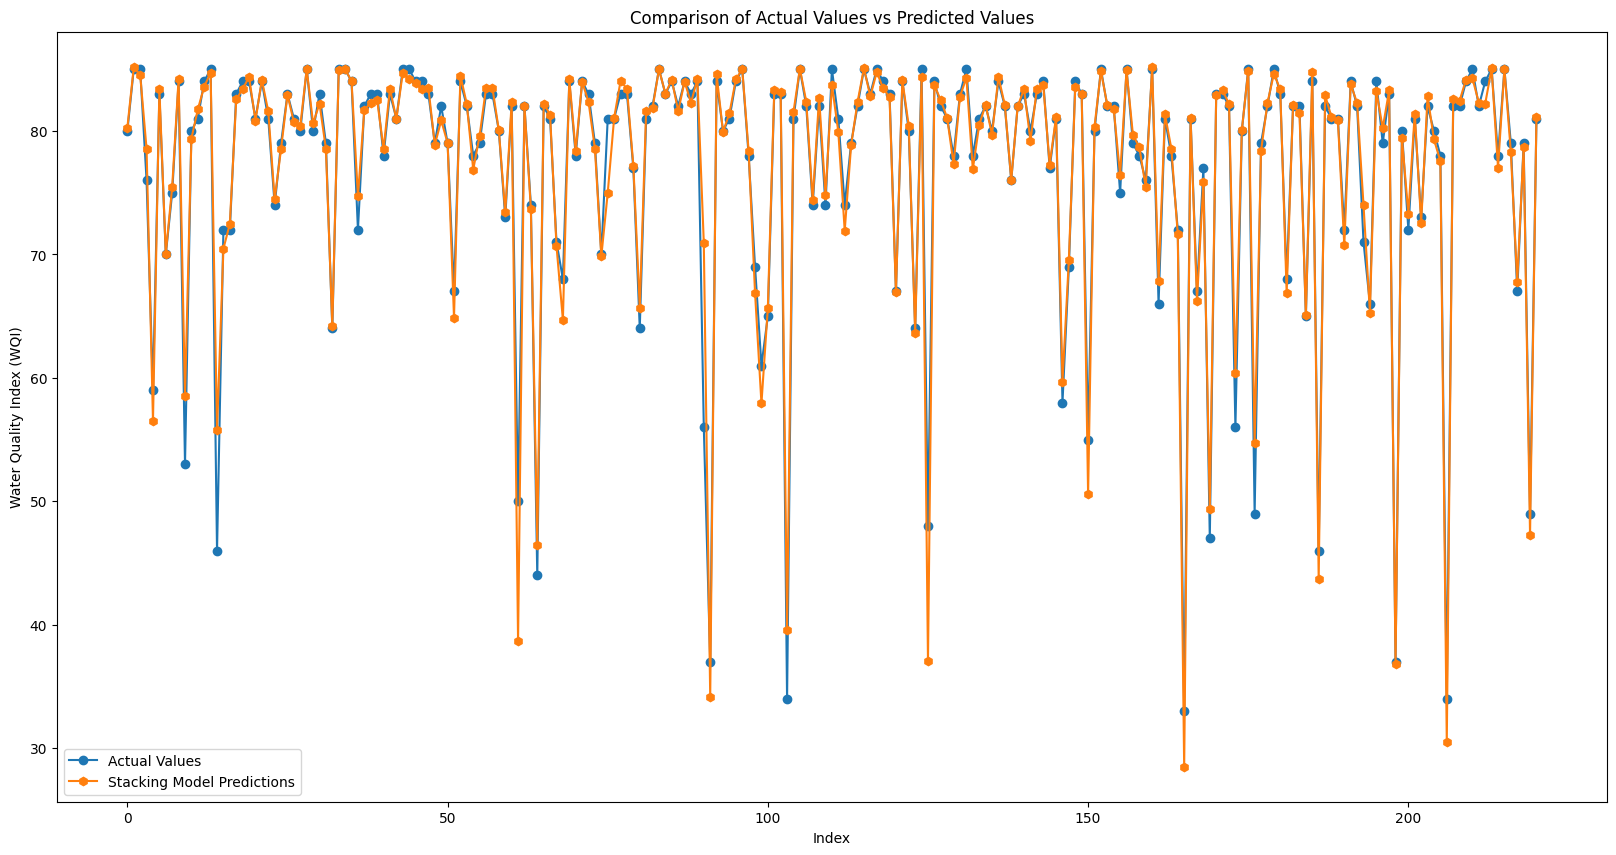

In [ ]:
plt.figure(figsize=(20, 10))
plt.plot(y_test.values, label='Actual Values', marker='o')
plt.plot(sm_pred, label='Stacking Model Predictions', marker='h')
plt.title('Comparison of Actual Values vs Predicted Values')
plt.xlabel('Index')
plt.ylabel('Water Quality Index (WQI)')
plt.legend()
plt.show()

# 5. Feature Importance


---

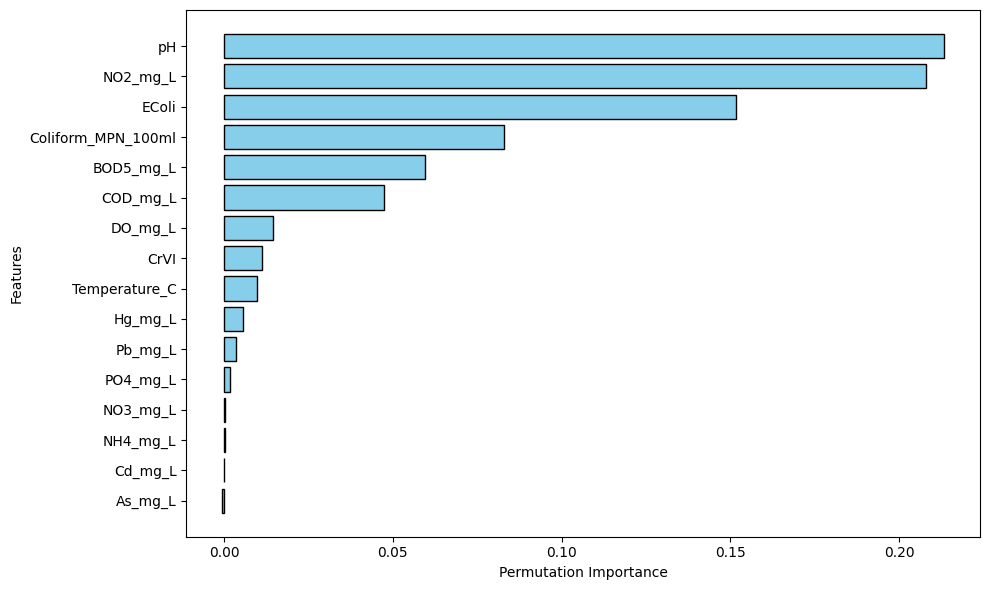

In [ ]:
# Calculate Permutation Importance
perm_importance = permutation_importance(stacking_model, X_test, y_test, n_repeats=30, random_state=42)

# Get the mean values and sort features by importance
sorted_idx = perm_importance.importances_mean.argsort()

# Plot the bar chart
plt.figure(figsize=(10, 6))
plt.barh(
    X_test.columns[sorted_idx], 
    perm_importance.importances_mean[sorted_idx], 
    color="skyblue", 
    edgecolor="black"
)
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()